## `meshlab` tutorial

Generate a boundary-layer mesh around multiple objects

### 1. Import packages
---

In [1]:
import numpy as np

from copy import deepcopy

from meshlab.data import Mesh, Contour
from meshlab.operations import insert_contour, compute_normals, advance_front, smooth_normals
from meshlab.visualization import plot_mesh

from functions.create_polygon import create_polygon

### 2. Define parameters
---

In [2]:
# Circle
num_points_c = 100            # Number of surface points
num_layers_c = 10             # Number of layers
height_c = 0.1                # First layer height
growth_rate_c = 1.2           # Ratio between two consecutive layers
center_c = [6.0, 2.0]         # Geometry center

# Square
num_points_s = 25             # Number of surface points
num_layers_s = 5              # Number of layers
height_s = 0.2                # First layer height
growth_rate_s = 1.1           # Ratio between two consecutive layers
center_s = [0.0, 0.0]         # Geometry center
smooth_steps_s = 5            # Number of smoothing steps
relaxation_s = 0.5            # Relaxation factor

### 3. Geometry definition
---

Circle

In [3]:
# Define angles between 0 and 2 * pi - remove the last point
alpha = np.linspace(0.0, 2.0 * np.pi, num_points_c, endpoint=False)

# Define a circle with points ordered in the counter-clockwise direction
points_c = np.column_stack(
    [
        np.cos(alpha),      # x
        np.sin(alpha),      # y
    ]
) + np.array(center_c)

Square

In [4]:
# Define vértices
vertices = np.array([
    [-1.0, -1.0],
    [ 1.0, -1.0],
    [ 1.0,  1.0],
    [-1.0,  1.0],
])

# Create points
points_s = create_polygon(
    vertices=vertices,
    points_per_edge=[num_points_s // 4] * len(vertices),
) + np.array(center_s)

### 4. Create boudary layer mesh
---

Initialize mesh, surface and front

In [5]:
# Initialize mesh and surfaces
mesh = Mesh()
circle = Contour("Circle")
square = Contour("Square")

# Insert contour into mesh
insert_contour(mesh, circle, points_c)
insert_contour(mesh, square, points_s)

# Create front based on surfaces
front_c = deepcopy(circle)
front_c.name = "Front [Circle]"

front_s = deepcopy(square)
front_s.name = "Front [Square]"

Create the first layer from the circle

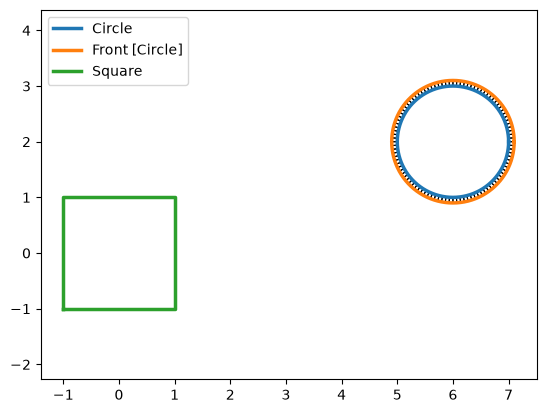

In [6]:
# Compute the front normals
normals_c = compute_normals(mesh, front_c)

# Advance the front creating new vertices based on the normals
front_c = advance_front(mesh, front_c, normals_c, height_c)

# Visualize the mesh
plot_mesh(mesh, [circle, front_c, square])

Now, create the first layer of the square

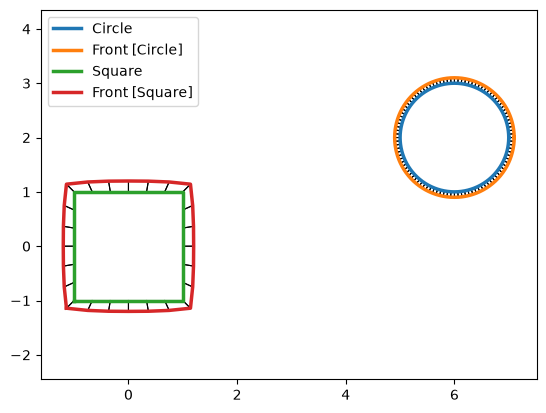

In [7]:
# Compute the front normals
normals_s = compute_normals(mesh, front_s)

# Smooth normals
for _ in range(smooth_steps_s):
    normals_s, _ = smooth_normals(normals_s, relaxation_s)

# Advance the front creating new vertices based on the normals
front_s = advance_front(mesh, front_s, normals_s, height_s)

# Visualize the mesh
plot_mesh(mesh, [circle, front_c, square, front_s])

The layers can be created in a loop

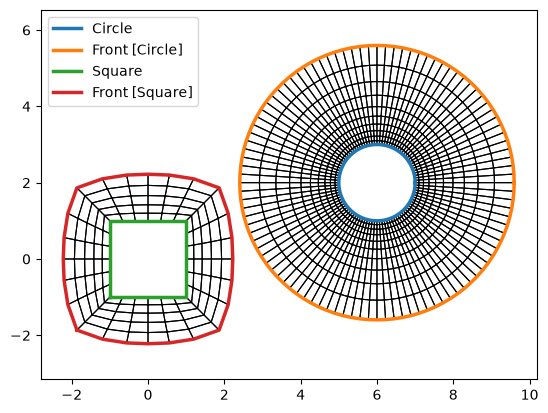

In [8]:
# Circle
for _ in range(num_layers_c - 1):
    # Compute the front normals
    normals_c = compute_normals(mesh, front_c)

    # Update height
    height_c *= growth_rate_c

    # Advance the front creating new vertices based on the normals
    front_c = advance_front(mesh, front_c, normals_c, height_c)

# Square
for _ in range(num_layers_s - 1):
    # Compute the front normals
    normals_s = compute_normals(mesh, front_s)

    # Smooth normals
    for _ in range(smooth_steps_s):
        normals_s, _ = smooth_normals(normals_s, relaxation_s)

    # Update height
    height_s *= growth_rate_s

    # Advance the front creating new vertices based on the normals
    front_s = advance_front(mesh, front_s, normals_s, height_s)

# Plot final mesh
plot_mesh(mesh, [circle, front_c, square, front_s])